# Milestone 2: Object detection with YOLOv8 on multi-object grid images

**Goal.** Train YOLOv8 to find every object in an image that contains many objects, and report each object's ID and location.

**Data.** The 38 Section 1 objects (OBJ IDs from the shared sheet), 3,605 photos at 224x224 from the Milestone 1 dataset. The train, validation and test split from Milestone 1 is reused, so no source photo can appear in more than one split.

**Pipeline in this notebook**

| Step | What happens |
|---|---|
| 1 | Setup: mount Drive, unzip the photos, define the object names |
| 2 | Select the Section 1 photos |
| 3 to 4 | Draw bounding boxes automatically with two detectors (YOLO-World and Grounding DINO) and measure how often they agree |
| 5 | Look at the boxes |
| 6 | Combine the boxes, apply the 20% drop limit, save `labels.csv` |
| 7 | Spot-check the final boxes by eye |
| 8 | Build the multi-object grid images (2x2 up to 5x5) with YOLO label files |
| 9 | Draw the saved labels back onto grids to verify them |

**Labels.** The shared dataset has object IDs but no bounding boxes, so the boxes were generated by two independent open-vocabulary detectors and checked as described in Steps 4 to 7.

# Task 1

### Step 1: Setup

**What this cell does.** Installs `ultralytics` (the YOLO library), imports the libraries, mounts Google Drive, and sets the folders: `M1_DIR` holds the Milestone 1 output (`dataset_224.zip` and `metadata.csv`), and `M2_DIR` is where this milestone's results are saved. It unzips the 224x224 photos to Colab's local disk and defines `NAMES`, the object name for each ID, exactly as written in the shared sheet. It also checks that a GPU is available.

**Output.** The pip progress bars and `Mounted at /content/drive`. No error means the setup worked.

In [ ]:
from google.colab import drive
drive.mount("/content/drive", force_remount=True)

import os
for p in ["/content/drive/MyDrive/IE7615_pytorch", "/content/drive/MyDrive/IE7615_detection"]:
    print(p, "->", os.listdir(p) if os.path.exists(p) else "missing")

Mounted at /content/drive
/content/drive/MyDrive/IE7615_pytorch -> ['eda_outputs', 'metadata.csv', 'manifests', 'dataset_224.zip', 'runs', 'runs_mobilenet', 'runs_transfer']
/content/drive/MyDrive/IE7615_detection -> ['raw_detections.json', 'labels.csv', 'dropped_photos.csv', 'per_object_summary.csv', 'grid_log_main.csv', 'evaluation', 'grid_log_Wang.csv', 'results.csv', 'runs']


In [ ]:
!pip -q install ultralytics

import os, io, json, re, random, shutil, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageOps, ImageEnhance
from tqdm.auto import tqdm
from google.colab import drive
drive.mount("/content/drive")

assert torch.cuda.is_available(), "Runtime > Change runtime type > T4 GPU"

M1_DIR = Path("/content/drive/MyDrive/IE7615_pytorch")      # Milestone 1 output (dataset_224.zip, metadata.csv)
M2_DIR = Path("/content/drive/MyDrive/IE7615_detection")    # Milestone 2 outputs (labels, checkpoints)
DATA = Path("/content/data")                                # local copy of the 224x224 photos
M2_DIR.mkdir(exist_ok=True)
if not (DATA / "manifests").exists():
    DATA.mkdir(exist_ok=True)
    zipfile.ZipFile(M1_DIR / "dataset_224.zip").extractall(DATA)

NAMES = {
    "OBJ001": "Basketball",
    "OBJ003": "NoteBook",
    "OBJ004": "Toy Car",
    "OBJ011": "mug",
    "OBJ012": "Computer Keyboard",
    "OBJ015": "Water Tumbler",
    "OBJ019": "Plant",
    "OBJ020": "Airpod",
    "OBJ021": "Toy Bunny",
    "OBJ022": "Guitar",
    "OBJ027": "Tennis ball",
    "OBJ030": "Tennis racket",
    "OBJ031": "UNO card box",
    "OBJ032": "Sound Card",
    "OBJ034": "Table Tennis Racket",
    "OBJ035": "Badminton racket",
    "OBJ036": "Pencil case",
    "OBJ037": "Candle",
    "OBJ038": "Perfume bottle",
    "OBJ039": "Scissors",
    "OBJ040": "Clutcher",
    "OBJ041": "Table fan",
    "OBJ042": "Mouth guard case",
    "OBJ043": "Swimming Goggels",
    "OBJ045": "Wayfarer Sunglasses",
    "OBJ046": "iWatch",
    "OBJ048": "Wireless powerbank",
    "OBJ052": "Spoon",
    "OBJ054": "Purse",
    "OBJ055": "Scientific Calculator",
    "OBJ057": "Power Bank",
    "OBJ060": "Sleep Mask",
    "OBJ062": "Headphones",
    "OBJ063": "Measuring Bottle",
    "OBJ064": "RGB Projector",
    "OBJ065": "Analog watch",
    "OBJ066": "hair oil",
    "OBJ073": "Bowl",
}
assert NAMES, "Fill in NAMES with the Section 1 rows from the shared sheet"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Step 2: Select the photos

**What this cell does.** Reads the Milestone 1 split files (train, val, test) and keeps only the photos of the 38 Section 1 objects. It leaves out `OBJ054_017`, which the assignment says is not a photo of the object. It also checks that every object has photos.



In [ ]:
meta = pd.read_csv(M1_DIR / "metadata.csv")
# OBJ054_017 is not a photo of the object: exclude it (metadata.csv maps original filenames to processed ones)
bad = set(meta.loc[meta["name"].str.upper().str.startswith("OBJ054_017"), "processed_path"])

parts = []
for split in ["train", "val", "test"]:
    df = pd.read_csv(DATA / "manifests" / f"{split}.csv")
    df = df[df.label.isin(NAMES) & ~df.filepath.isin(bad)].copy()
    df["split"] = split
    parts.append(df)
photos = pd.concat(parts, ignore_index=True)

missing_ids = sorted(set(NAMES) - set(photos.label))
assert not missing_ids, f"These IDs from NAMES have no photos in the manifests: {missing_ids}"
print("Object IDs:", photos.label.nunique(), "| photos:", len(photos), "| excluded OBJ054_017:", len(bad))
print(photos.groupby("split").size().to_dict())

Object IDs: 38 | photos: 3605 | excluded OBJ054_017: 1
{'test': 563, 'train': 2509, 'val': 533}


**Output.** `Object IDs: 38 | photos: 3605 | excluded OBJ054_017: 1`, then the split sizes: train 2,509, val 533, test 563. That is about 70/15/15, and roughly 95 photos per object.

### Step 3: Draw boxes automatically with two detectors

**What this cell does.** Each photo contains one object whose name is known, so each detector only has to find where it is. Both detectors get the object's name as a text prompt and the highest-scoring box is kept:
- **YOLO-World** (`yolov8l-worldv2`)
- **Grounding DINO** (`grounding-dino-base`)

The raw boxes are saved to `raw_detections.json` on Drive so a disconnect does not lose this step.



In [ ]:
# Two independent open-vocabulary detectors. Each photo has ONE object whose name we know,
# so each detector only has to find where it is: we keep its top-scoring box.
from ultralytics import YOLOWorld
from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection

def run_yoloworld(photos):
    model = YOLOWorld("yolov8l-worldv2.pt")
    out = {}
    for label, g in tqdm(photos.groupby("label"), desc="YOLO-World"):
        model.set_classes([NAMES[label]])
        fps = list(g.filepath)
        for i in range(0, len(fps), 32):
            chunk = fps[i:i + 32]
            res = model.predict([str(DATA / p) for p in chunk], conf=0.05, imgsz=640, verbose=False)
            for fp, r in zip(chunk, res):
                if len(r.boxes):
                    j = int(r.boxes.conf.argmax())
                    out[fp] = (r.boxes.xyxy[j].tolist(), float(r.boxes.conf[j]))
    return out

@torch.no_grad()
def run_gdino(photos, model_id="IDEA-Research/grounding-dino-base"):
    proc = AutoProcessor.from_pretrained(model_id)
    model = AutoModelForZeroShotObjectDetection.from_pretrained(model_id).to("cuda").eval()
    out = {}
    for label, g in tqdm(photos.groupby("label"), desc="Grounding DINO"):
        text = NAMES[label].lower().strip() + "."
        fps = list(g.filepath)
        for i in range(0, len(fps), 2):
            chunk = fps[i:i + 2]
            imgs = [Image.open(DATA / p).convert("RGB") for p in chunk]
            inputs = proc(images=imgs, text=[text] * len(imgs), return_tensors="pt", padding=True).to("cuda")
            outputs = model(**inputs)
            sizes = [im.size[::-1] for im in imgs]
            try:
                res = proc.post_process_grounded_object_detection(outputs, inputs.input_ids, threshold=0.2,
                                                                  text_threshold=0.2, target_sizes=sizes)
            except TypeError:   # older transformers versions call it box_threshold
                res = proc.post_process_grounded_object_detection(outputs, inputs.input_ids, box_threshold=0.2,
                                                                  text_threshold=0.2, target_sizes=sizes)
            for fp, r in zip(chunk, res):
                if len(r["boxes"]):
                    j = int(r["scores"].argmax())
                    out[fp] = (r["boxes"][j].tolist(), float(r["scores"][j]))
    del model; torch.cuda.empty_cache()
    return out

A = run_yoloworld(photos)
B = run_gdino(photos)
print(f"YOLO-World found a box for {len(A)}/{len(photos)} photos | Grounding DINO for {len(B)}/{len(photos)}")
json.dump({"A": A, "B": B}, open(M2_DIR / "raw_detections.json", "w"))   # saved so a disconnect does not cost you this step

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


YOLO-World:   0%|          | 0/38 [00:00<?, ?it/s]

requirements: Ultralytics requirement ['git+https://github.com/ultralytics/CLIP.git'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 37 packages in 755ms
Prepared 2 packages in 4.67s
Installed 2 packages in 4ms
 + clip==1.0 (from git+https://github.com/ultralytics/CLIP.git@7ffa84b3bfa40c42ecc1c77147a855e69cb2dd40)
 + ftfy==6.3.1

requirements: AutoUpdate success ✅ 6.0s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect




  0%|                                               | 0.00/338M [00:00<?, ?iB/s]
  2%|▉                                     | 8.20M/338M [00:00<00:04, 85.9MiB/s]
  7%|██▋                                    | 22.9M/338M [00:00<00:02, 126MiB/s]
 11%|████▍                                  | 38.0M/338M [00:00<00:02, 140MiB/s]
 16%|██████                                 | 52.3M/338M [00:00<00:02, 143MiB/s]
 20%|███████▋                               | 66.6M/338M [00:00<00:01, 144MiB/s]
 24%|█████████▍                             | 82.1M/338M [00:00<00:01, 151MiB/s]
 29%|███████████▏                           | 96.5M/338M [00:00<00:02, 122MiB/s]
 33%|█████████████                           | 110M/338M [00:00<00:01, 128MiB/s]
 36%|██████████████▌                         | 123M/338M [00:00<00:01, 128MiB/s]
 42%|████████████████▊                       | 142M/338M [00:01<00:01, 148MiB/s]
 47%|██████████████████▊                     | 158M/338M [00:01<00:01, 155MiB/s]
 51%|████████████████████▌ 

preprocessor_config.json:   0%|          | 0.00/457 [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  933MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/1182 [00:00<?, ?it/s]

Grounding DINO:   0%|          | 0/38 [00:00<?, ?it/s]

YOLO-World found a box for 1698/3605 photos | Grounding DINO for 3562/3605


**Output.** The progress bars show one step per object (38). The last line gives how many photos each model boxed: `YOLO-World 1698/3605` and `Grounding DINO 3562/3605` (98.8%). YOLO-World's count is low because its confidence cutoff (0.05) was too strict, and the next cell reruns it with a lower cutoff.

### Step 4: Rerun YOLO-World with a lower cutoff and measure agreement

**What this cell does.** Reruns YOLO-World with `conf=0.001` so it keeps the low-confidence boxes it had thrown away. These replace the earlier YOLO-World boxes. Then, for every photo, it checks whether the two models' boxes overlap (IoU of at least 0.6).

In [ ]:
import gc
def run_yoloworld(photos, conf=0.001):
    model = YOLOWorld("yolov8l-worldv2.pt")
    out = {}
    for label, g in tqdm(photos.groupby("label"), desc="YOLO-World"):
        model.set_classes([NAMES[label]])
        fps = list(g.filepath)
        for i in range(0, len(fps), 32):
            chunk = fps[i:i + 32]
            res = model.predict([str(DATA / p) for p in chunk], conf=conf, imgsz=640, max_det=10, verbose=False)
            for fp, r in zip(chunk, res):
                if len(r.boxes):
                    j = int(r.boxes.conf.argmax())
                    out[fp] = (r.boxes.xyxy[j].tolist(), float(r.boxes.conf[j]))
    del model; gc.collect(); torch.cuda.empty_cache()
    return out

A = run_yoloworld(photos)
json.dump({"A": A, "B": B}, open(M2_DIR / "raw_detections.json", "w"))

def iou(a, b):
    ix1, iy1, ix2, iy2 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    ua = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / ua if ua > 0 else 0.0

photos["has_A"] = photos.filepath.isin(A); photos["has_B"] = photos.filepath.isin(B)
photos["agree"] = [fp in A and fp in B and iou(A[fp][0], B[fp][0]) >= 0.6 for fp in photos.filepath]
print(f"YOLO-World: {len(A)}/{len(photos)} | Grounding DINO: {len(B)}/{len(photos)} | boxes agree (IoU >= 0.6): {photos.agree.mean():.1%}")
rate = photos.groupby("label")[["has_A", "has_B", "agree"]].mean().round(2)
rate.insert(0, "name", [NAMES[l] for l in rate.index])
print(rate.sort_values("agree").head(12))

YOLO-World:   0%|          | 0/38 [00:00<?, ?it/s]

YOLO-World: 3243/3605 | Grounding DINO: 3562/3605 | boxes agree (IoU >= 0.6): 72.4%
                       name  has_A  has_B  agree
label                                           
OBJ065         Analog watch   0.97   1.00   0.34
OBJ034  Table Tennis Racket   0.49   0.97   0.37
OBJ060           Sleep Mask   0.65   1.00   0.41
OBJ038       Perfume bottle   0.49   1.00   0.41
OBJ043     Swimming Goggels   0.85   1.00   0.44
OBJ042     Mouth guard case   0.89   1.00   0.48
OBJ046               iWatch   0.86   1.00   0.48
OBJ045  Wayfarer Sunglasses   0.94   1.00   0.53
OBJ032           Sound Card   0.92   1.00   0.53
OBJ020               Airpod   0.68   0.94   0.55
OBJ048   Wireless powerbank   1.00   1.00   0.62
OBJ040             Clutcher   0.76   1.00   0.64


**Output.**
- `YOLO-World: 3243/3605 | Grounding DINO: 3562/3605 | boxes agree (IoU >= 0.6): 72.4%`. After the rerun YOLO-World boxes 90% of the photos, and the two models agree on 72.4%.
- The table lists the 12 objects with the lowest agreement. `has_A` and `has_B` are the share of photos where YOLO-World and Grounding DINO produced a box, and `agree` is the share where the two boxes overlap. The weakest are OBJ065 Analog watch (34%) and OBJ034 Table Tennis Racket (37%). Every object has some agreement, so no object name failed completely.

### Step 5: Look at the boxes

**What this cell does.** Defines `peek_objects` and shows 10 random objects with 6 random photos each. The **red** box is YOLO-World and the **blue** box is Grounding DINO.


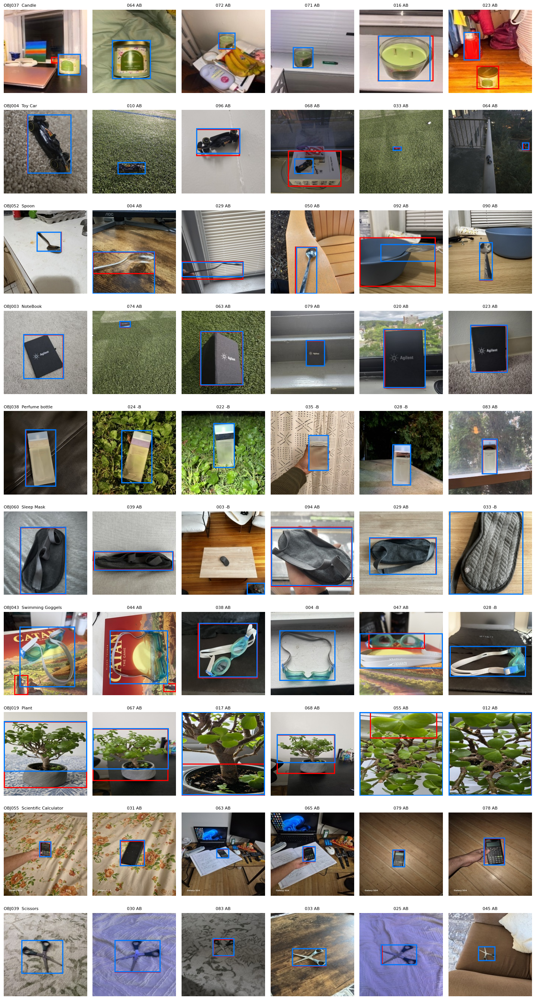

In [ ]:
def peek_objects(k=10, per_obj=6, seed=None):
    rng = np.random.default_rng(seed)
    labels = [str(l) for l in rng.choice(sorted(photos.label.unique()), size=k, replace=False)]
    fig, axes = plt.subplots(k, per_obj, figsize=(2.4 * per_obj, 2.7 * k))
    for row, lab in enumerate(labels):
        sub = photos[photos.label == lab]
        sub = sub.sample(min(per_obj, len(sub)), random_state=int(rng.integers(1_000_000_000)))
        for col in range(per_obj):
            ax = axes[row, col]; ax.axis("off")
            if col >= len(sub):
                continue
            r = sub.iloc[col]
            im = Image.open(DATA / r.filepath).convert("RGB"); d = ImageDraw.Draw(im)
            a, b = A.get(r.filepath), B.get(r.filepath)
            if a: d.rectangle(a[0], outline=(255, 0, 0), width=3)
            if b: d.rectangle(b[0], outline=(0, 120, 255), width=3)
            ax.imshow(im)
            ax.set_title(f"{lab}  {NAMES[lab]}" if col == 0 else f"{Path(r.filepath).stem[-3:]} {'A' if a else '-'}{'B' if b else '-'}",
                         fontsize=8, loc="left" if col == 0 else "center")
    plt.tight_layout(); plt.show()

peek_objects(k=10, per_obj=6)      # run again for a different random set of objects

**Output.** An image grid with one object per row. The first photo in each row is titled with the object ID and name. The other titles show the photo number and `A` and/or `B`, meaning which detector found a box (`A-` means only YOLO-World, `-B` only Grounding DINO). This is a visual check that the boxes cover the whole object and not just a part of it.

### Step 6: Combine the boxes and save `labels.csv`

**What this cell does.** Decides the final box for every photo:
- **accept**: both models found a box and they overlap (IoU of at least 0.5). The final box is the average of the two.
- **disagree**: both found a box but they differ. The more confident box is used.
- **single**: only one model found a box. That box is used.
- **none**: no box was found, so the photo is dropped.

Photos with no usable box are dropped first, then the weakest-agreement photos, but never more than 20% of any Object ID (the assignment's limit). `MANUAL_DROP` and `MANUAL_PICK` are empty, so no manual overrides were applied. The results are saved to Drive as `labels.csv`, `dropped_photos.csv` and `per_object_summary.csv`.



In [ ]:
THR_IOU = 0.5        # two models agree if their boxes overlap at least this much
MAX_DROP = 0.20      # assignment rule: leave out at most 20% of the photos of any Object ID
MANUAL_DROP = []     # photos with no usable box, e.g. ["OBJ011_025.jpg"]
MANUAL_PICK = {}     # photos where you chose a box by eye: "A" = YOLO-World (red), "B" = Grounding DINO (blue), e.g. {"OBJ065_012.jpg": "B"}

def iou(a, b):
    ix1, iy1, ix2, iy2 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    ua = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / ua if ua > 0 else 0.0

def ok_box(b):
    return b is not None and (b[2] - b[0]) >= 4 and (b[3] - b[1]) >= 4

recs = []
for r in photos.itertuples():
    fp = r.filepath; fname = Path(fp).name
    a = A.get(fp); b = B.get(fp)
    a = a if a and ok_box(a[0]) else None
    b = b if b and ok_box(b[0]) else None
    pick = MANUAL_PICK.get(fname)
    chosen = a if pick == "A" else (b if pick == "B" else None)
    if fname in MANUAL_DROP:
        status, q, box, why = "manual", -2.0, None, "manual review: wrong or missing box"
    elif chosen is not None:
        status, q, box, why = "picked", 3.0, chosen[0], ""
    elif a is None and b is None:
        status, q, box, why = "none", -1.0, None, "no detection by either model"
    elif a is not None and b is not None:
        v = iou(a[0], b[0])
        if v >= THR_IOU:
            status, q, why = "accept", 2 + v, ""
            box = [(x + y) / 2 for x, y in zip(a[0], b[0])]
        else:
            status, q, why = "disagree", v, f"models disagree (IoU {v:.2f})"
            box = a[0] if a[1] >= b[1] else b[0]
    else:
        c = a if a is not None else b
        status, q, box, why = "single", 0.6 + 0.3 * c[1], c[0], "only one model found a box"
    recs.append(dict(filepath=fp, label=r.label, split=r.split, status=status, q=q, box=box, why=why))
L = pd.DataFrame(recs)

# Drop the unlabelable photos, then the weakest-agreement ones, never more than 20% per Object ID
L["is_dropped"] = False
for label, g in L.groupby("label"):
    cap = int(MAX_DROP * len(g))
    forced = g[g.status.isin(["none", "manual"])].index
    L.loc[forced, "is_dropped"] = True
    if len(forced) > cap:
        print(f"WARNING {label}: {len(forced)} photos without a usable box exceed the 20% cap ({cap}). Hand-label some of them.")
    budget = cap - len(forced)
    if budget > 0:
        weak = g[g.status.isin(["disagree", "single"])].sort_values("q").head(budget).index
        L.loc[weak, "is_dropped"] = True

used = L[~L.is_dropped & L.box.notna()].copy()
for i, k in enumerate(["x1", "y1", "x2", "y2"]):
    used[k] = used.box.map(lambda b, i=i: float(np.clip(b[i], 0, 224)))
used = used[["filepath", "label", "split", "x1", "y1", "x2", "y2", "status"]].reset_index(drop=True)
dropped = L[L.is_dropped][["filepath", "label", "split", "status", "why"]]

used.to_csv(M2_DIR / "labels.csv", index=False)
dropped.to_csv(M2_DIR / "dropped_photos.csv", index=False)

summary = L.groupby("label").agg(photos=("filepath", "size"), dropped=("is_dropped", "sum")).astype(int)
summary["used"] = summary.photos - summary.dropped
summary["drop_pct"] = (100 * summary.dropped / summary.photos).round(1)
summary.to_csv(M2_DIR / "per_object_summary.csv")
print(f"Used {len(used)} of {len(L)} photos | dropped {len(dropped)} ({100*len(dropped)/len(L):.1f}%)")
print("Status of used photos:", used.status.value_counts().to_dict())
print("Drop reasons:", dropped.why.str.replace(r"\(IoU.*\)", "", regex=True).value_counts().to_dict())
print("Max drop % in any Object ID:", summary.drop_pct.max())
print(summary.sort_values("drop_pct", ascending=False).head(10))

Used 3048 of 3605 photos | dropped 557 (15.5%)
Status of used photos: {'accept': 2655, 'single': 250, 'disagree': 143}
Drop reasons: {'models disagree ': 421, 'only one model found a box': 116, 'no detection by either model': 20}
Max drop % in any Object ID: 20.0
        photos  dropped  used  drop_pct
label                                  
OBJ003      95       19    76      20.0
OBJ004     100       20    80      20.0
OBJ012      95       19    76      20.0
OBJ040      95       19    76      20.0
OBJ032      95       19    76      20.0
OBJ020      95       19    76      20.0
OBJ064      95       19    76      20.0
OBJ057      95       19    76      20.0
OBJ065      95       19    76      20.0
OBJ038      95       19    76      20.0


**Output.**
- `Used 3048 of 3605 photos | dropped 557 (15.5%)`.
- Of the photos used, 2,655 (87%) have two agreeing boxes, 250 have a box from one model only, and 143 have disagreeing boxes.
- Drop reasons: 421 disagreeing, 116 single-model, 20 with no detection.
- `Max drop % in any Object ID: 20.0` shows the 20% limit is respected. The table lists the objects with the highest drop rate, all at the 20% cap (19 or 20 photos each).

### Step 7: Spot-check the final boxes

**What this cell does.** Draws the final box (red) on 24 random photos from the "both models agreed" group and 24 random photos from the "weak" group (only one model, or the models disagreed). This is the manual quality check of the automatically generated labels.



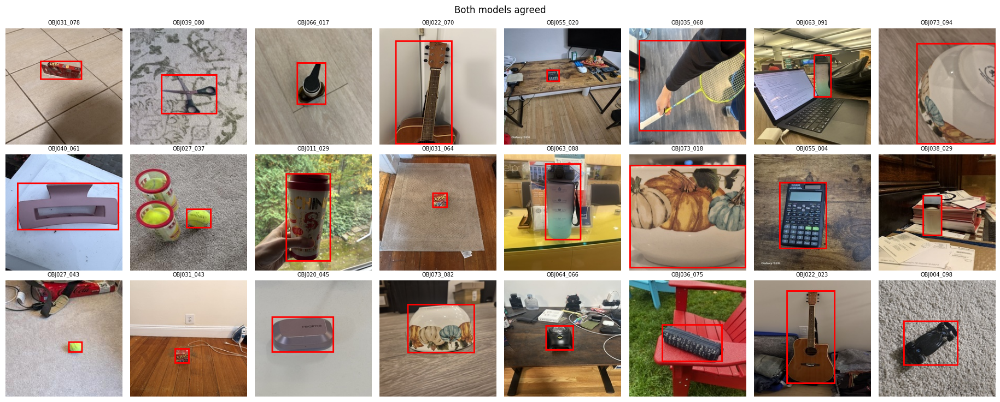

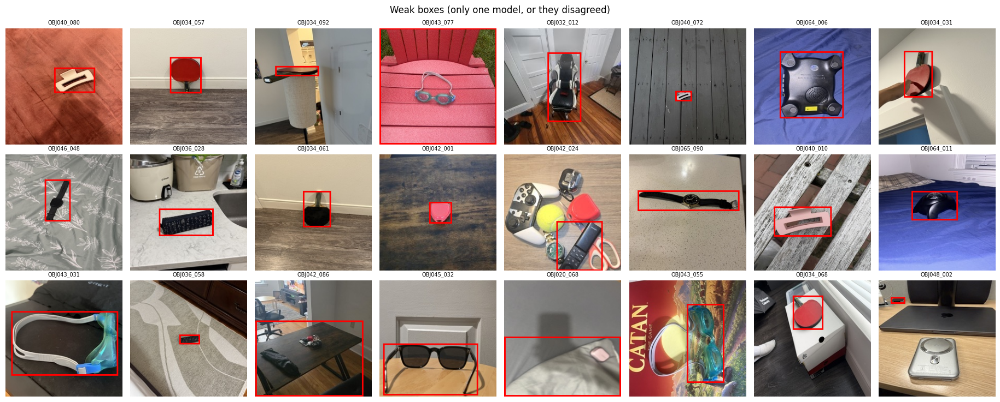

In [ ]:
def sheet(df, n=48, cols=8, title=""):
    df = df.head(n)
    rows = max(1, int(np.ceil(len(df) / cols)))
    fig, axes = plt.subplots(rows, cols, figsize=(2.3 * cols, 2.5 * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes: ax.axis("off")
    for ax, r in zip(axes, df.itertuples()):
        im = Image.open(DATA / r.filepath).convert("RGB")
        ImageDraw.Draw(im).rectangle([r.x1, r.y1, r.x2, r.y2], outline=(255, 0, 0), width=3)
        ax.imshow(im); ax.set_title(f"{Path(r.filepath).stem}", fontsize=7)
    plt.suptitle(title); plt.tight_layout(); plt.show()

sheet(used[used.status == "accept"].sample(24, random_state=0), 24, title="Both models agreed")
sheet(used[used.status != "accept"].sample(24, random_state=0), 24, title="Weak boxes (only one model, or they disagreed)")

**Output.** Two image sheets, with each title showing the photo name.
- **Both models agreed:** 0 of 24 boxes were clearly wrong. A few boxes are slightly loose, for example one that includes a hand holding a racket.
- **Weak boxes:** about 6 of 24 were clearly wrong (a box on a chair, a box covering most of the photo, a box on a neighbouring item) and 2 were uncertain.

These counts support the estimate that roughly 3 to 5% of all final boxes may be inaccurate. The weak photos were kept because the assignment limits dropping to 20% per object.

### Step 8: Build the multi-object grid images

**What this cell does.** Builds grid images by placing 224x224 photos side by side, in five sizes: 2x2 (448x448), 3x3 (672x672), 4x4 (896x896), 5x4 (1120x896) and 5x5 (1120x1120). Rules:
- All photos in a grid come from the same split, so no source photo ends up in two splits (checked by an `assert`).
- Each photo in a grid is a different photo.
- Each photo gets a random horizontal flip and a small brightness change. The box is mirrored and shifted to match.
- A YOLO label file is written for every grid (class, centre x, centre y, width, height, all relative to the grid size), plus a `data.yaml` file and a `grid_log_main.csv` on Drive that records which photos went into which grid.



In [ ]:
from PIL import ImageOps, ImageEnhance
if "used" not in globals():
    used = pd.read_csv(M2_DIR / "labels.csv")          # teammates: this is the shared labels file

TILE = 224
GRIDS = {"2x2": (2, 2), "3x3": (3, 3), "4x4": (4, 4), "5x4": (5, 4), "5x5": (5, 5)}   # (columns, rows)
GRID_WEIGHTS = [0.15, 0.20, 0.25, 0.20, 0.20]
N_GRIDS = {"train": 400, "val": 80, "test": 80}
SEED = 47                                  # teammates: use your own seed and a different PREFIX
PREFIX = ""
GRID_DIR = Path("/content/grids")          # local disk. Keep image data out of GitHub and out of the shared folder.

CLASS_IDS = sorted(used.label.unique())
cls_index = {l: i for i, l in enumerate(CLASS_IDS)}

def make_grids(used, split, n, seed, out_root=GRID_DIR, prefix=""):
    rng = random.Random(seed)
    pool = used[used.split == split].to_dict("records")
    img_dir = out_root / split / "images"; lab_dir = out_root / split / "labels"
    img_dir.mkdir(parents=True, exist_ok=True); lab_dir.mkdir(parents=True, exist_ok=True)
    log = []
    for k in range(n):
        gname = rng.choices(list(GRIDS), weights=GRID_WEIGHTS)[0]
        cols, rows = GRIDS[gname]
        W, H = cols * TILE, rows * TILE
        canvas = Image.new("RGB", (W, H))
        lines, ids = [], []
        for t, r in enumerate(rng.sample(pool, cols * rows)):      # distinct photos inside one grid
            im = Image.open(DATA / r["filepath"]).convert("RGB")
            if im.size != (TILE, TILE):
                im = im.resize((TILE, TILE))
            x1, y1, x2, y2 = r["x1"], r["y1"], r["x2"], r["y2"]
            if rng.random() < 0.5:                                  # horizontal flip: mirror the box too
                im = ImageOps.mirror(im); x1, x2 = TILE - x2, TILE - x1
            im = ImageEnhance.Brightness(im).enhance(rng.uniform(0.8, 1.2))
            ox, oy = (t % cols) * TILE, (t // cols) * TILE
            canvas.paste(im, (ox, oy))
            cx, cy = (ox + (x1 + x2) / 2) / W, (oy + (y1 + y2) / 2) / H
            lines.append(f"{cls_index[r['label']]} {cx:.6f} {cy:.6f} {(x2 - x1) / W:.6f} {(y2 - y1) / H:.6f}")
            ids.append(r["filepath"])
        name = f"{prefix}{split}_{k:04d}_{gname}"
        canvas.save(img_dir / f"{name}.jpg", quality=95)
        (lab_dir / f"{name}.txt").write_text("\n".join(lines))
        log.append(dict(grid=name, split=split, size=gname, n_objects=len(lines), photos="|".join(ids)))
    return pd.DataFrame(log)

if GRID_DIR.exists():
    shutil.rmtree(GRID_DIR)
logs = pd.concat([make_grids(used, s, N_GRIDS[s], SEED + i, prefix=PREFIX) for i, s in enumerate(["train", "val", "test"])])
logs.to_csv(M2_DIR / f"grid_log_{PREFIX or 'main'}.csv", index=False)

# No source photo may appear in more than one split
srcs = {s: set("|".join(logs[logs.split == s].photos).split("|")) for s in ["train", "val", "test"]}
assert not (srcs["train"] & srcs["val"]) and not (srcs["train"] & srcs["test"]) and not (srcs["val"] & srcs["test"])

(GRID_DIR / "data.yaml").write_text(
    f"path: {GRID_DIR}\ntrain: train/images\nval: val/images\ntest: test/images\nnames:\n"
    + "\n".join(f"  {i}: {l}" for i, l in enumerate(CLASS_IDS)) + "\n")
print(logs.groupby(["split", "size"]).size().unstack(fill_value=0))
print("objects per split:", logs.groupby("split").n_objects.sum().to_dict(), "| classes:", len(CLASS_IDS))

size   2x2  3x3  4x4  5x4  5x5
split                         
test     9   14   19   20   18
train   49   80  106   80   85
val     15   16   22    9   18
objects per split: {'test': 1316, 'train': 6337, 'val': 1186} | classes: 38


**Output.** The table shows how many grid images were built for each split and size. Adding up each row gives 400 train, 80 val and 80 test grids (560 in total), and all five sizes appear in every split. The last line counts the labelled objects (boxes) inside those grids: 6,455 in train, 1,237 in val and 1,166 in test. A 2x2 grid holds 4 objects and a 5x5 grid holds 25. It also confirms classes: 38.

### Step 9: Verify the grid labels

**What this cell does.** Reads the saved label files and draws them back onto two training grids, so the labels can be checked against the images. Each red box should sit on an object and the yellow text is the object ID.



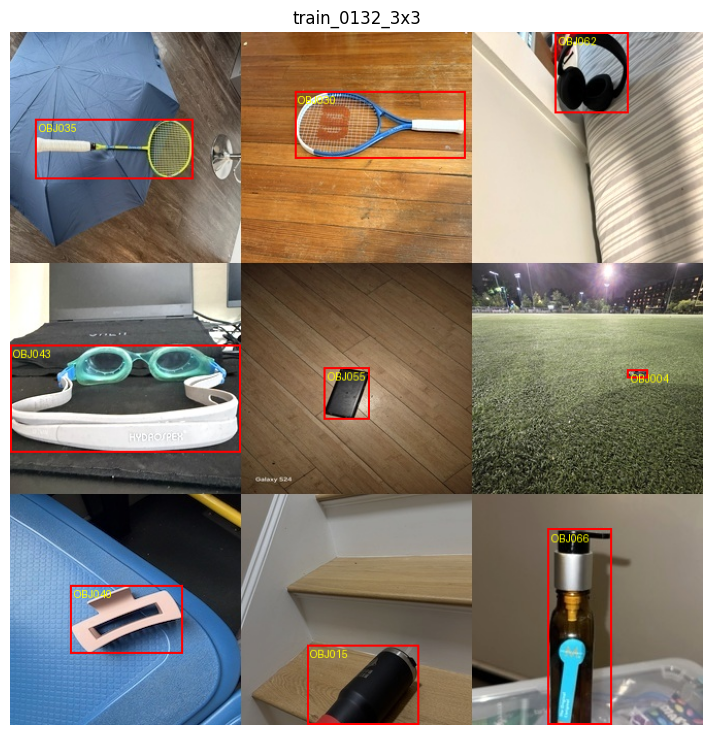

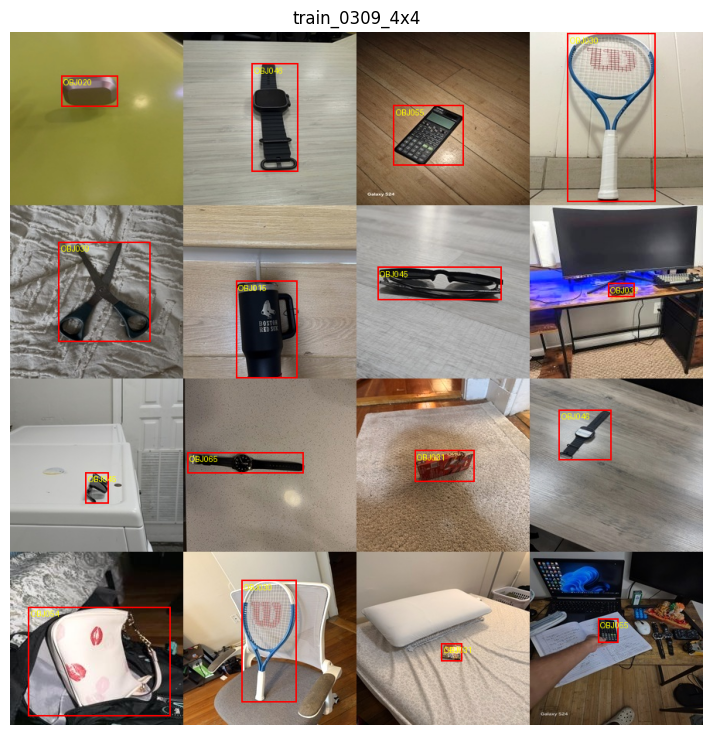

In [ ]:
def show_grid(name, split="train"):
    im = Image.open(GRID_DIR / split / "images" / f"{name}.jpg").convert("RGB")
    W, H = im.size; d = ImageDraw.Draw(im)
    for line in (GRID_DIR / split / "labels" / f"{name}.txt").read_text().splitlines():
        c, cx, cy, w, h = line.split(); c = int(c)
        cx, cy, w, h = float(cx) * W, float(cy) * H, float(w) * W, float(h) * H
        d.rectangle([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2], outline=(255, 0, 0), width=2)
        d.text((cx - w / 2 + 3, cy - h / 2 + 3), CLASS_IDS[c], fill=(255, 255, 0))
    plt.figure(figsize=(9, 9)); plt.imshow(im); plt.axis("off"); plt.title(name); plt.show()

for name in logs[logs.split == "train"].grid.sample(2, random_state=0):
    show_grid(name)

**Output.** Two example grids: `train_0132_3x3` and `train_0309_4x4`. Every box sits on the correct object, including small objects and photos that were flipped, and the IDs match what is shown. This confirms that the box coordinates survive the grid placement and flipping. These two images also serve as examples of the training data.

# Task 2

# Step 1: Prepare the training data

**What this cell does:**

This cell serves as a critical quality assurance and validation step before training the YOLOv8 model. It ensures that the dataset was generated correctly in Task 1 and matches the logged metadata. Specifically, it:

1. **Imports Core Libraries**: Brings in `Path` for filesystem path manipulations, `pandas` for data log analysis, `torch` to confirm GPU availability, and `ultralytics` for YOLO operations.
2. **Defines Directories and Constants**: Links to the local directory where multi-object grid images are stored (`/content/grids`) and the Google Drive directory where labels, logs, and checkpoints reside.
3. **Verifies GPU Acceleration**: Asserts that a CUDA-enabled GPU (e.g., Tesla T4) is available and prints its hardware name to guarantee training will be fast.
4. **Verifies Dataset Existence**: Assures that the `data.yaml` file configuration exists.
5. **Performs Log and File System Checks**:
    - Reads the `grid_log_main.csv` master file tracking grid layouts.
    - Loops through each split (`train`, `val`, and `test`) and asserts that the actual folder contains the exact expected number of grid images (400 train, 80 validation, 80 test).
    - Verifies that for every generated `.jpg` image, there is a corresponding `.txt` file containing the bounding box coordinates in YOLO format.
    - Assures that the file stems of the images and labels match each other and the master log exactly.

In [ ]:
from pathlib import Path
import pandas as pd
import torch
from ultralytics import YOLO

GRID_DIR = Path("/content/grids")
M2_DIR = Path("/content/drive/MyDrive/IE7615_detection")

SEED = 42
PREFIX = ""

assert torch.cuda.is_available(), "Please enable T4 GPU in Colab."

DATA_YAML = GRID_DIR / "data.yaml"
assert DATA_YAML.exists(), "Run Task 1 Step 8 first."

log_path = M2_DIR / "grid_log_main.csv"
assert log_path.exists(), "Main-grid log not found."

grid_log = pd.read_csv(log_path)

for split, expected_count in {
    "train": 400,
    "val": 80,
    "test": 80
}.items():

    image_dir = GRID_DIR / split / "images"
    label_dir = GRID_DIR / split / "labels"

    image_names = {p.stem for p in image_dir.glob("*.jpg")}
    label_names = {p.stem for p in label_dir.glob("*.txt")}

    expected_names = set(
        grid_log.loc[grid_log["split"] == split, "grid"]
    )

    assert len(expected_names) == expected_count
    assert image_names == expected_names
    assert label_names == expected_names

    print(f"{split}: {len(image_names)} grids verified")

print("GPU:", torch.cuda.get_device_name(0))
print("Dataset:", DATA_YAML)
print("Main grids are ready!")

train: 400 grids verified
val: 80 grids verified
test: 80 grids verified
GPU: Tesla T4
Dataset: /content/grids/data.yaml
Main grids are ready!


**Output:** A success print confirming `train`, `val`, and `test` splits are verified, identifying the active GPU, and validating that the main grids are ready for training.

# Step 2: Train YOLOv8s

**What this cell does:**

This cell initializes and runs the training process for the **YOLOv8s** (small) object detection model on our custom multi-object grid dataset. Specifically, it configures and executes the following steps:

1. **Environment & Parameters Setup**:
   - Sets hyperparameters such as `SEED = 42` for reproducibility.
   - Configures the input size to `IMG_SIZE = 1120` (matching the resolution of our largest 5x5 grids to preserve detail).
   - Establishes a batch size of `8` (optimized to prevent out-of-memory errors on a standard T4 GPU) and targets training for `80 epochs`.

2. **Directory & Safety Check**:
   - Configures the output path to save checkpoints under `/content/drive/MyDrive/IE7615_detection/runs/yolov8s_main_seed42`.
   - **Checkpoint Protection:** Before starting, it checks if an existing `last.pt` file exists. If one is found, it raises a `RuntimeError` to prevent you from accidentally overwriting your training progress (in which case, you should use the Resume cell instead).

3. **Model Initialization**:
   - Loads the pre-trained `yolov8s.pt` base model from Ultralytics.
   - Automatically overrides the classification head to output **38 classes** (matching our specific Section 1 objects) instead of the default COCO 80 classes.

4. **Model Training (`model.train`)**:
   - Points to our generated `/content/grids/data.yaml` dataset configuration.
   - Disables `mosaic` augmentation (`mosaic=0.0`) since our grid images are already dense combinations of different individual photos.
   - Employs Automatic Mixed Precision (`amp=True`) to accelerate training and reduce GPU VRAM utilization.
   - Uses deterministic algorithms (`deterministic=True`) and limits dataset loader threads (`workers=2`).

In [ ]:
from ultralytics import YOLO
from pathlib import Path

SEED = 42
IMG_SIZE = 1120
BATCH_SIZE = 8
EPOCHS = 80

PROJECT_DIR = M2_DIR / "runs"
RUN_NAME = "yolov8s_main_seed42"

RUN_DIR = PROJECT_DIR / RUN_NAME
LAST_CKPT = RUN_DIR / "weights" / "last.pt"

PROJECT_DIR.mkdir(parents=True, exist_ok=True)

if LAST_CKPT.exists():
    raise RuntimeError(
        "An existing checkpoint was found. "
        "Use the resume cell instead of starting over."
    )

model = YOLO("yolov8s.pt")

results = model.train(
    data=str(DATA_YAML),

    epochs=EPOCHS,
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    mosaic=0.0,

    device=0,
    seed=SEED,
    deterministic=True,
    amp=True,

    patience=80,
    workers=2,
    cache=False,

    project=str(PROJECT_DIR),
    name=RUN_NAME,
    exist_ok=True,
    save=True,
    save_period=5,
    plots=True,

    verbose=True
)

print("Training completed!")
print("Results saved to:", RUN_DIR)
print("Best model:", RUN_DIR / "weights" / "best.pt")
print("Last checkpoint:", LAST_CKPT)

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/grids/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1120, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=yolov8s_main_seed42, nbs=64, nms=None, opset=None, optimize=False

**Output:**
- Progress logs for each epoch showing training losses (box, class, dfl) and validation metrics on the validation split.
- A concluding confirmation showing where the best-performing weights (`best.pt`) and final epoch weights (`last.pt`) are securely saved on your Google Drive.

# Step 3: Resume training if Colab disconnects

**What this cell does:**

This cell is a fallback mechanism designed to safely resume the YOLOv8s training process if your Google Colab runtime disconnects or crashes during the 80 epochs of training. Specifically, it executes the following logic:

1. **Path Initialization**: Re-establishes the directories targeting your Google Drive (`M2_DIR`) and local grid directory (`GRID_DIR`).
2. **Check for Dataset**: Asserts that the `/content/grids/data.yaml` configuration is present (if Colab disconnected completely, you must unzip/regenerate the grids first as outlined in Step 8 of Task 1).
3. **Checkpoint Verification**: Locates the `last.pt` weight checkpoint file (which YOLO updates automatically at the end of every epoch inside `runs/yolov8s_main_seed42/weights/`). It asserts that this file exists on your Google Drive; if it doesn't, training cannot be resumed.
4. **Resuming Training (`model.train(resume=True)`)**:
   - Loads the exact training state, learning rate schedule, optimizer states, and epoch index from `last.pt`.
   - Reruns the training loop seamlessly starting from the exact epoch where it was interrupted, keeping all original hyperparameter configurations intact.




In [ ]:
from pathlib import Path
from ultralytics import YOLO

M2_DIR = Path("/content/drive/MyDrive/IE7615_detection")
GRID_DIR = Path("/content/grids")

DATA_YAML = GRID_DIR / "data.yaml"

LAST_CKPT = (
    M2_DIR
    / "runs"
    / "yolov8s_main_seed42"
    / "weights"
    / "last.pt"
)

assert DATA_YAML.exists(), "Regenerate the grids first."
assert LAST_CKPT.exists(), "No checkpoint found on Drive."

print("Resuming from:", LAST_CKPT)

model = YOLO(str(LAST_CKPT))

results = model.train(
    resume=True,
    data=str(DATA_YAML)
)

print("Resumed training completed!")

# Step 4: Evaluate the trained model

**What this cell does:**

This cell evaluates the performance of our newly trained object detector using the test dataset split. It ensures that the model can successfully generalize to unseen grids containing random arrangements of Section 1 objects. Specifically, it executes the following steps:

1. **Best Model Retrieval**:
   - Locates and verifies the existence of `best.pt` under the Google Drive run directory (`/content/drive/MyDrive/IE7615_detection/runs/yolov8s_main_seed42/weights/best.pt`). This file represents the epoch checkpoint that scored the highest mean Average Precision (mAP) on the validation split during training.

2. **Validation/Evaluation Mode Setup (`model.val`)**:
   - Loads the weights of the best-performing model into memory.
   - Configures the validation execution on the independent **test** split (`split="test"`).
   - Sets the image resolution to `imgsz=1120` to preserve the grid boundaries and structural layouts.
   - Forces evaluation on the GPU (`device=0`) with an optimized validation batch size of `batch=8`.
   - Saves evaluation visual plots (confusion matrix, F1 curve, precision-recall curve) directly into Google Drive under a new run folder named `yolov8s_main_seed42_test`.

3. **Metrics Calculation & Printing**:
   - Outputs standard object detection validation metrics:
     - **Precision**: The ratio of true positive detections to total predicted boxes.
     - **Recall**: The percentage of ground truth boxes correctly predicted.
     - **mAP@50**: Mean Average Precision calculated at an Intersection over Union (IoU) threshold of 0.50.
     - **mAP@75**: mAP computed at a stricter IoU threshold of 0.75.
     - **mAP@50-95**: The primary competition metric, averaging mAP across IoU thresholds from 0.50 to 0.95 in 0.05 increments.




In [ ]:
from ultralytics import YOLO

BEST_MODEL = (
    M2_DIR
    / "runs"
    / "yolov8s_main_seed42"
    / "weights"
    / "best.pt"
)

assert BEST_MODEL.exists(), "Best model checkpoint not found."

model = YOLO(str(BEST_MODEL))

metrics = model.val(
    data=str(DATA_YAML),
    split="test",
    imgsz=1120,
    batch=8,
    device=0,
    plots=True,
    project=str(M2_DIR / "runs"),
    name="yolov8s_main_seed42_test"
)

print("\n===== YOLOv8s Test Results =====")
print(f"Precision: {metrics.box.mp:.4f}")
print(f"Recall:    {metrics.box.mr:.4f}")
print(f"mAP@50:    {metrics.box.map50:.4f}")
print(f"mAP@75:    {metrics.box.map75:.4f}")
print(f"mAP@50-95: {metrics.box.map:.4f}")

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,140,290 parameters, 0 gradients, 28.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 88.2±51.7 MB/s, size: 292.0 KB)
val: Scanning /content/grids/test/labels... 80 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 80/80 491.7it/s 0.2s
val: New cache created: /content/grids/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 1.6it/s 6.4s
                   all         80       1166      0.922      0.916      0.928       0.88
                OBJ001         29         39      0.982          1      0.995      0.984
                OBJ003         21         27      0.933      0.778      0.805      0.778
                OBJ004         20         25      0.915          1      0.983      0.902
                OBJ011         22         28      0.948          1      0.995      0.981
   

**Output:** A breakdown of detection precision and recall per object class (truncated in standard logs) followed by a final evaluation block summarizing the five main test metrics.

# Task 3: Evaluate

### Step 1: Evaluate on the test grids

**What this cell does.** Loads the best YOLOv8s checkpoint (`best.pt`) and evaluates it on the 80 test grids. It reports the overall precision, recall, mAP@0.5 and mAP@0.5:0.95, then builds a per-object table with each object's number of test instances, precision, recall, AP@0.5 and AP@0.5:0.95. The table is saved to `test_per_object.csv` on Drive and sorted from weakest to strongest object.

**Note.** The boxes in the test grids were generated automatically in Task 1 (Steps 3 to 6), not drawn by hand. These scores therefore measure how well YOLOv8s matches those generated boxes.

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
from ultralytics import YOLO

M2_DIR = Path("/content/drive/MyDrive/IE7615_detection")
GRID_DIR = Path("/content/grids")
DATA_YAML = GRID_DIR / "data.yaml"
EVAL_DIR = M2_DIR / "evaluation"
EVAL_DIR.mkdir(parents=True, exist_ok=True)
BEST_MODEL = M2_DIR / "runs" / "yolov8s_main_seed42" / "weights" / "best.pt"

assert DATA_YAML.exists() and len(list((GRID_DIR / "test" / "images").glob("*.jpg"))) == 80, \
    "Test grids missing. Run Task 1 Step 1 and Step 8 first."
assert BEST_MODEL.exists(), "best.pt not found on Drive."

model = YOLO(str(BEST_MODEL))
metrics = model.val(data=str(DATA_YAML), split="test", imgsz=1120, batch=8, device=0,
                    plots=True, project=str(EVAL_DIR), name="test_eval", exist_ok=True, verbose=False)

# overall results
overall = {"precision": metrics.box.mp, "recall": metrics.box.mr,
           "mAP@0.5": metrics.box.map50, "mAP@0.5:0.95": metrics.box.map}
print("Overall test results:")
for k, v in overall.items():
    print(f"  {k:<13} {v:.4f}")

# per-object results
counts = pd.Series([int(line.split()[0]) for f in (GRID_DIR / "test" / "labels").glob("*.txt")
                    for line in f.read_text().splitlines()]).value_counts()
names = globals().get("NAMES", {})
rows = []
for i, c in enumerate(metrics.box.ap_class_index):
    oid = model.names[int(c)]
    rows.append({"object_id": oid, "name": names.get(oid, ""), "instances": int(counts.get(int(c), 0)),
                 "precision": metrics.box.p[i], "recall": metrics.box.r[i],
                 "AP@0.5": metrics.box.ap50[i], "AP@0.5:0.95": metrics.box.ap[i]})
per_obj = pd.DataFrame(rows).sort_values("AP@0.5").reset_index(drop=True)
per_obj.to_csv(EVAL_DIR / "test_per_object.csv", index=False)
pd.DataFrame([overall]).to_csv(EVAL_DIR / "test_overall.csv", index=False)

print(f"\nPer-object results ({len(per_obj)} objects), weakest first:")
print(per_obj.round(3).to_string(index=False))
print(f"\nObjects with AP@0.5 below 0.80: {(per_obj['AP@0.5'] < 0.80).sum()} | "
      f"at or above 0.95: {(per_obj['AP@0.5'] >= 0.95).sum()}")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,140,290 parameters, 0 gradients, 28.5 GFLOPs
val: Fast image access ✅ (ping: 0.1±0.1 ms, read: 2405.5±237.7 MB/s, size: 360.8 KB)
val: Scanning /content/grids/test/labels... 80 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 80/80 2.0Kit/s 0.0s
val: New cache created: /content/grids/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 1.8it/s 5.6s
                   all         80       1316      0.925      0.896      0.922      0.871
Speed: 11.3ms preprocess, 32.3ms inference, 0.0ms loss, 4.0ms po

**Output.** On the 80 test grids (1,316 objects), YOLOv8s reached a precision of **0.925**, a recall of **0.896**, an mAP@0.5 of **0.922** and an mAP@0.5:0.95 of **0.871**. Recall is lower than precision, so the model more often misses an object than reports one that is not there.

These grids are a fresh arrangement of the test photos, not the exact grids scored in Task 2. Step 8 was rerun in a new session and produced 1,316 test objects instead of the 1,166 scored in Task 2 Step 4. The photos are the same unseen test photos (Step 8 checks that no photo is shared between splits), only placed into different grids. The scores stay close to Task 2's (mAP@0.5 0.922 vs 0.928, mAP@0.5:0.95 0.871 vs 0.880), which shows the model's performance does not depend on one particular grid layout.

The per-object table shows that most objects are detected very reliably. 20 of the 38 objects reach an AP@0.5 of 0.95 or higher, and 14 of them reach 0.995. Only 3 objects fall below 0.80:
- **OBJ042 Mouth guard case** is by far the weakest (AP@0.5 **0.474**, recall 0.394). The model finds fewer than 4 in 10 of them.
- **OBJ048 Wireless powerbank** (0.711) and **OBJ003 NoteBook** (0.733) are next. Both are flat, plain rectangular objects that can be confused with other flat items such as the Power Bank, Sound Card and Scientific Calculator.

Several of the weakest objects (OBJ042, OBJ065 Analog watch, OBJ060 Sleep Mask, OBJ043 Swimming Goggles, OBJ020 Airpod) also had low agreement between YOLO-World and Grounding DINO in Task 1 Step 4, so their training boxes are likely less consistent. For OBJ043 and OBJ065 the gap between AP@0.5 and AP@0.5:0.95 is unusually large (0.914 vs 0.684, and 0.803 vs 0.679), meaning the model finds them but its boxes do not fit tightly, which matches the less consistent labels.

Results are saved to `evaluation/test_per_object.csv` and `evaluation/test_overall.csv`, and the Ultralytics plots (confusion matrix, PR curve) to `evaluation/test_eval`.

### Step 2: Save example detections on test grids

**What this cell does.** Picks one test grid of each size (2x2, 3x3, 4x4, 5x4 and 5x5) and runs the model on it. For each grid it shows the ground-truth boxes from Task 1 (green) next to the model's detections with their confidence scores, and counts how many objects were found correctly (same object ID and IoU of at least 0.5 with the ground-truth box). Each example is saved as an image to `evaluation/examples`.

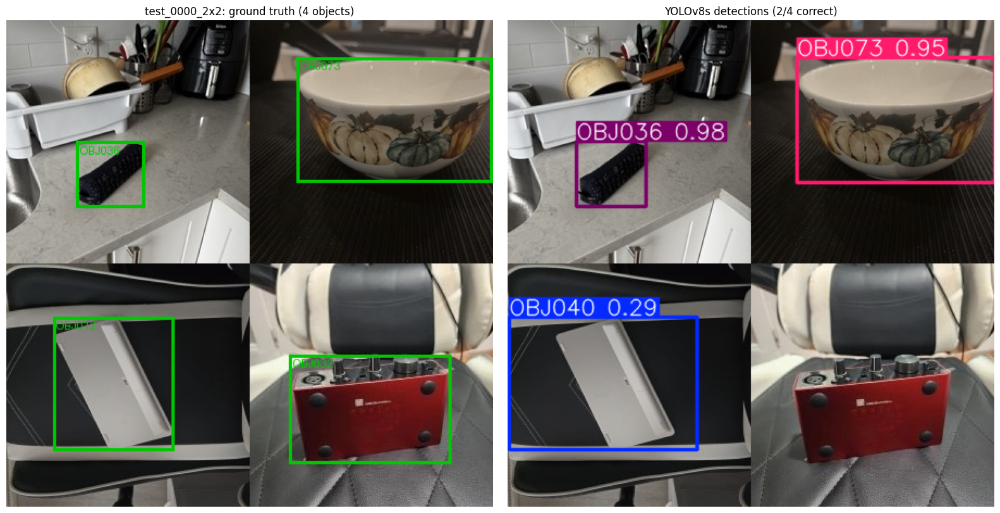

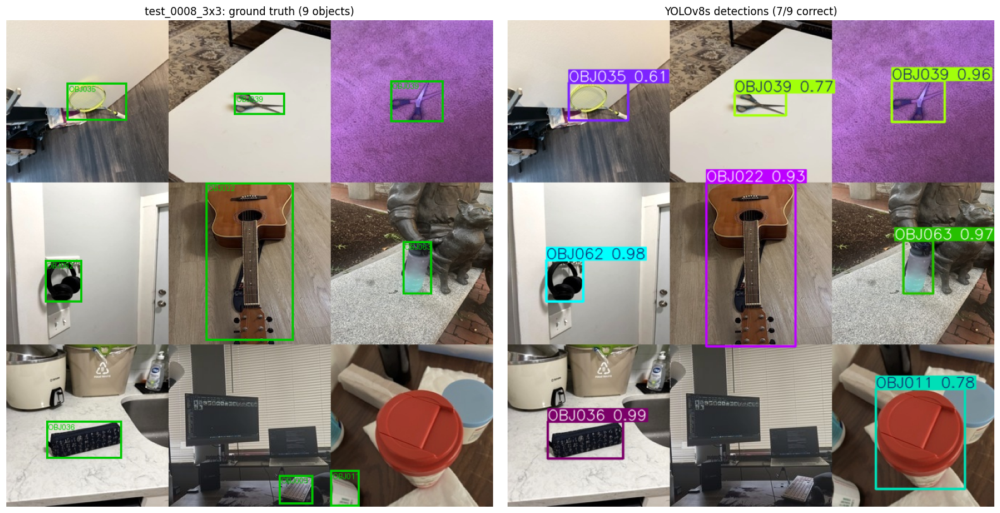

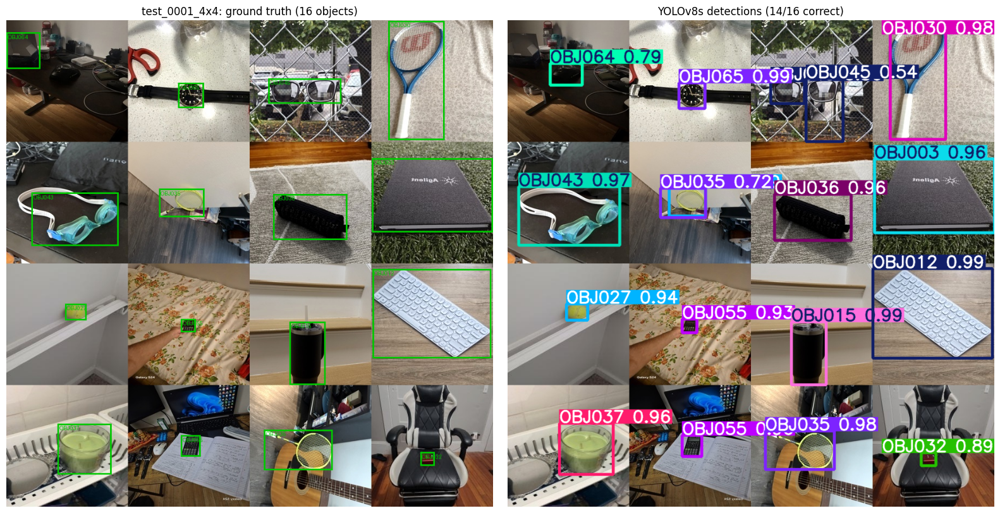

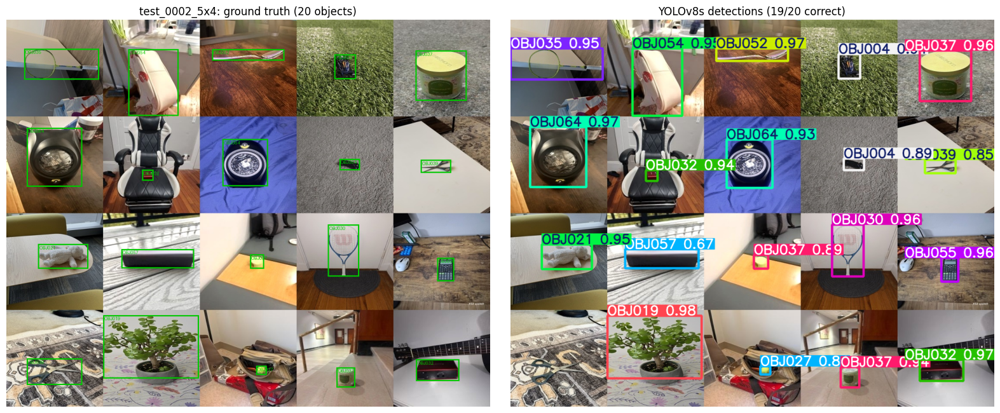

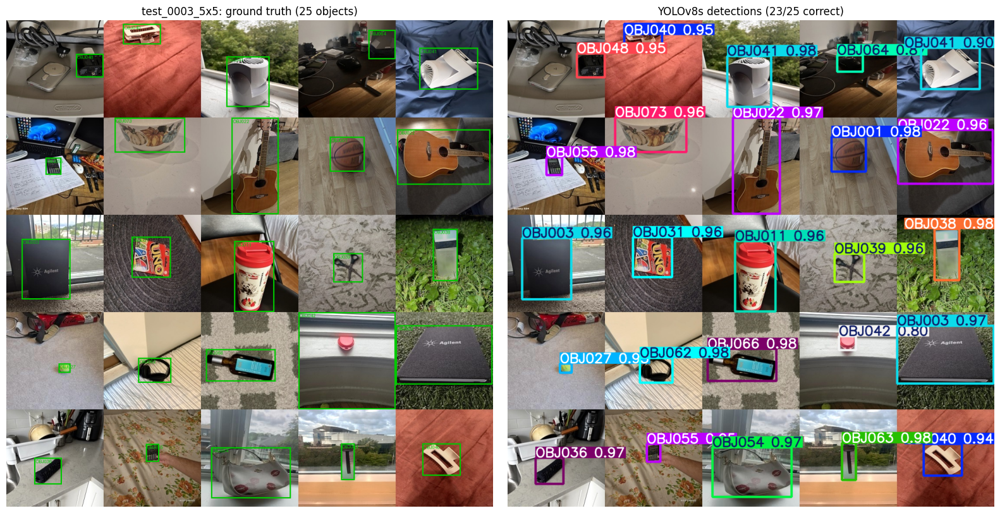

         grid  objects  detections  correct  missed  extra
test_0000_2x2        4           3        2       2      1
test_0008_3x3        9           8        7       2      1
test_0001_4x4       16          18       14       2      4
test_0002_5x4       20          19       19       1      0
test_0003_5x5       25          25       23       2      2


In [ ]:
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

EX_DIR = EVAL_DIR / "examples"
EX_DIR.mkdir(exist_ok=True)
test_imgs = sorted((GRID_DIR / "test" / "images").glob("*.jpg"))
picks = [next(p for p in test_imgs if p.stem.endswith(s)) for s in ["2x2", "3x3", "4x4", "5x4", "5x5"]
         if any(p.stem.endswith(s) for p in test_imgs)]


def read_gt(img_path, W, H):
    boxes = []
    for line in (GRID_DIR / "test" / "labels" / f"{img_path.stem}.txt").read_text().splitlines():
        c, cx, cy, w, h = line.split()
        cx, cy, w, h = float(cx) * W, float(cy) * H, float(w) * W, float(h) * H
        boxes.append((int(c), cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2))
    return boxes


def iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0])); iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    return inter / ((a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter + 1e-9)


summary = []
for p in picks:
    gt_img = Image.open(p).convert("RGB"); W, H = gt_img.size
    gt = read_gt(p, W, H)
    d = ImageDraw.Draw(gt_img)
    for c, x1, y1, x2, y2 in gt:
        d.rectangle([x1, y1, x2, y2], outline=(0, 200, 0), width=3)
        d.text((x1 + 3, y1 + 2), model.names[c], fill=(0, 200, 0))

    res = model.predict(str(p), imgsz=1120, conf=0.25, verbose=False)[0]
    preds = [(int(c), *b) for c, b in zip(res.boxes.cls.tolist(), res.boxes.xyxy.tolist())]
    pred_img = Image.fromarray(res.plot()[:, :, ::-1])

    matched, used = 0, set()
    for g in gt:
        for j, pr in enumerate(preds):
            if j not in used and pr[0] == g[0] and iou(g[1:], pr[1:]) >= 0.5:
                matched += 1; used.add(j); break
    summary.append(dict(grid=p.stem, objects=len(gt), detections=len(preds), correct=matched,
                        missed=len(gt) - matched, extra=len(preds) - matched))

    fig, ax = plt.subplots(1, 2, figsize=(16, 8 * H / W))
    ax[0].imshow(gt_img); ax[0].set_title(f"{p.stem}: ground truth ({len(gt)} objects)")
    ax[1].imshow(pred_img); ax[1].set_title(f"YOLOv8s detections ({matched}/{len(gt)} correct)")
    for a in ax: a.axis("off")
    plt.tight_layout(); plt.savefig(EX_DIR / f"{p.stem}_example.png", dpi=100); plt.show()

ex_summary = pd.DataFrame(summary)
ex_summary.to_csv(EX_DIR / "examples_summary.csv", index=False)
print(ex_summary.to_string(index=False))

**Output.** Across the five example grids, the model correctly found **65 of 74 objects** (87.8%), with 9 missed and 8 extra detections. A detection counts as correct only if it has the right object ID and its box overlaps the ground-truth box with an IoU of at least 0.5. An "extra" detection is one that did not match any ground-truth object: either a wrong object ID or a box placed in the wrong spot.

| Grid | Objects | Correct | Missed | Extra |
| :--- | :---: | :---: | :---: | :---: |
| 2x2 | 4 | 2 | 2 | 1 |
| 3x3 | 9 | 7 | 2 | 1 |
| 4x4 | 16 | 14 | 2 | 4 |
| 5x4 | 20 | 19 | 1 | 0 |
| 5x5 | 25 | 23 | 2 | 2 |

The larger grids performed best: the 5x4 grid missed only 1 object out of 20, and the 5x5 grid found 23 of 25. The 2x2 grid was the weakest at 2 of 4. One likely reason is object scale. All grids are resized to 1120 pixels, so the four tiles of a 2x2 grid are enlarged about 2.5x, making its objects much bigger than in the denser grids that make up most of the training data. With only five example grids these counts are small, so the overall test results from Step 1 remain the main measure of performance.

The example images are saved to `evaluation/examples`, and the counts to `evaluation/examples/examples_summary.csv`.

### Step 3: Detection function for any grid image

**What this cell does.** Defines `detect_objects`, which takes any grid image (a file path or a loaded image) and returns every object the model finds. For each detection it gives the object ID, the object name, the confidence score, the bounding box in pixels (`x1, y1, x2, y2`), and the grid cell (row and column) the object sits in. Results are sorted from top-left to bottom-right, in reading order. The function is then run on one test grid, and the result is printed, saved to `evaluation/detect_objects_example.json` and drawn on the image.

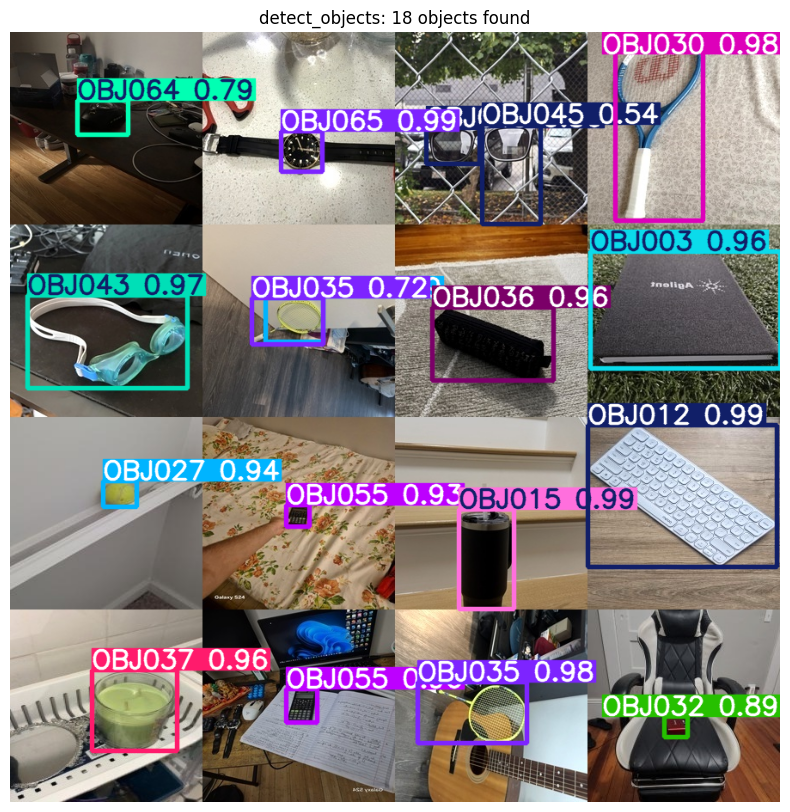

test_0001_4x4.jpg: 18 objects found
object_id                  name  confidence                          box  row  col
   OBJ064         RGB Projector       0.788   [78.5, 79.1, 137.5, 119.3]    0    0
   OBJ065          Analog watch       0.993 [315.5, 115.1, 363.3, 162.6]    0    1
   OBJ045   Wayfarer Sunglasses       0.539 [549.3, 107.2, 617.6, 223.1]    0    2
   OBJ045   Wayfarer Sunglasses       0.360 [484.4, 111.0, 546.4, 153.1]    0    2
   OBJ030         Tennis racket       0.977   [704.1, 0.9, 806.1, 220.0]    0    3
   OBJ043      Swimming Goggels       0.973  [20.1, 306.7, 206.2, 414.7]    1    0
   OBJ035      Badminton racket       0.717 [281.2, 309.5, 364.3, 363.4]    1    1
   OBJ027           Tennis ball       0.291 [297.1, 309.9, 364.1, 360.7]    1    1
   OBJ036           Pencil case       0.960 [491.5, 320.6, 632.1, 405.1]    1    2
   OBJ003              NoteBook       0.960 [675.9, 255.3, 896.0, 391.8]    1    3
   OBJ027           Tennis ball       0.942 [108.0,

In [ ]:
import json


def detect_objects(image, conf=0.25, tile=224, show=False):
    """Detect objects in a grid image.

    image: file path, PIL image or numpy array
    returns: list of dicts with object_id, name, confidence, box [x1, y1, x2, y2] in pixels, and grid row/col
    """
    if isinstance(image, (str, Path)):
        image = Image.open(image).convert("RGB")
    res = model.predict(image, imgsz=1120, conf=conf, verbose=False)[0]
    names = globals().get("NAMES", {})
    out = []
    for c, s, b in zip(res.boxes.cls.tolist(), res.boxes.conf.tolist(), res.boxes.xyxy.tolist()):
        oid = model.names[int(c)]
        x1, y1, x2, y2 = [round(v, 1) for v in b]
        out.append({"object_id": oid, "name": names.get(oid, ""), "confidence": round(s, 3),
                    "box": [x1, y1, x2, y2],
                    "row": int(((y1 + y2) / 2) // tile), "col": int(((x1 + x2) / 2) // tile)})
    out.sort(key=lambda d: (d["row"], d["col"]))
    if show:
        plt.figure(figsize=(10, 10)); plt.imshow(res.plot()[:, :, ::-1]); plt.axis("off")
        plt.title(f"detect_objects: {len(out)} objects found"); plt.show()
    return out


# demo on one test grid
demo = next(p for p in test_imgs if p.stem.endswith("4x4"))
found = detect_objects(demo, show=True)
json.dump({"image": demo.name, "detections": found}, open(EVAL_DIR / "detect_objects_example.json", "w"), indent=2)

print(f"{demo.name}: {len(found)} objects found")
print(pd.DataFrame(found).to_string(index=False))

**Output.** `detect_objects` returned **18 detections** for the 16-cell test grid `test_0001_4x4`. Each one lists the object ID, name, confidence, pixel box and grid cell, sorted in reading order. The full result is saved to `evaluation/detect_objects_example.json`.

Two cells contain two detections each, which accounts for the 2 extra detections:
- **Row 0, column 2** has two Wayfarer Sunglasses (OBJ045) boxes with confidences of 0.539 and 0.360. The model detected the same object twice, once over the whole pair and once over a single lens.
- **Row 1, column 1** has a Badminton racket (OBJ035, 0.717) and a Tennis ball (OBJ027, 0.291) with almost identical boxes. The model was unsure which object it was and reported both labels.

In both cases the lower-confidence detection is the wrong one, and every other cell has exactly one detection, most with confidence above 0.93.

### Step 4: Improve the detections with post-processing

**What this cell does.** Step 3 showed two kinds of extra detections: the same object detected twice, and one object given two different labels with nearly the same box. This step tests two ways of removing them without retraining:
- **Class-agnostic NMS** (`agnostic_nms=True`): when boxes overlap heavily, only the most confident one is kept, even if their labels differ. Normally YOLO only removes overlapping boxes that share the same label.
- **One per cell**: every cell of a grid holds exactly one object, so only the most confident detection in each 224-pixel cell is kept.

All three versions (baseline, agnostic NMS, one per cell) are run on all 80 test grids at the same confidence threshold (0.25). A detection counts as correct if it has the right object ID and an IoU of at least 0.5 with a ground-truth box. For each version the cell reports correct detections, missed objects, extra detections, precision, recall, F1, and how many grids got exactly the right number of detections.

In [ ]:
def predict_boxes(img_path, agnostic=False, conf=0.25):
    r = model.predict(str(img_path), imgsz=1120, conf=conf, agnostic_nms=agnostic, verbose=False)[0]
    return [(int(c), s, *b) for c, s, b in zip(r.boxes.cls.tolist(), r.boxes.conf.tolist(), r.boxes.xyxy.tolist())]


def keep_one_per_cell(preds, tile=224):
    best = {}
    for p in preds:
        cell = (int(((p[3] + p[5]) / 2) // tile), int(((p[2] + p[4]) / 2) // tile))
        if cell not in best or p[1] > best[cell][1]:
            best[cell] = p
    return list(best.values())


def score(gt, preds):
    used, tp = set(), 0
    for g in gt:
        cands = [(j, pr) for j, pr in enumerate(preds) if j not in used and pr[0] == g[0] and iou(g[1:], pr[2:]) >= 0.5]
        if cands:
            j, _ = max(cands, key=lambda t: t[1][1]); used.add(j); tp += 1
    return tp, len(preds) - tp, len(gt) - tp


versions = {"baseline": [], "agnostic_nms": [], "one_per_cell": []}
for p in tqdm(test_imgs):
    W, H = Image.open(p).size
    gt = read_gt(p, W, H)
    base = predict_boxes(p)
    for v, preds in [("baseline", base), ("agnostic_nms", predict_boxes(p, agnostic=True)),
                     ("one_per_cell", keep_one_per_cell(base))]:
        tp, fp, fn = score(gt, preds)
        versions[v].append(dict(grid=p.stem, objects=len(gt), detections=len(preds), tp=tp, fp=fp, fn=fn))

rows = []
for v, recs in versions.items():
    d = pd.DataFrame(recs)
    tp, fp, fn = d.tp.sum(), d.fp.sum(), d.fn.sum()
    prec, rec = tp / (tp + fp), tp / (tp + fn)
    rows.append(dict(version=v, objects=d.objects.sum(), detections=d.detections.sum(), correct=tp,
                     missed=fn, extra=fp, precision=prec, recall=rec, F1=2 * prec * rec / (prec + rec),
                     exact_count_grids=f"{(d.detections == d.objects).sum()}/{len(d)}"))
post = pd.DataFrame(rows)
post.to_csv(EVAL_DIR / "postprocessing_comparison.csv", index=False)
print(post.round(4).to_string(index=False))

  0%|          | 0/80 [00:00<?, ?it/s]

     version  objects  detections  correct  missed  extra  precision  recall     F1 exact_count_grids
    baseline     1316        1303     1200     116    103     0.9210  0.9119 0.9164             25/80
agnostic_nms     1316        1295     1198     118     97     0.9251  0.9103 0.9177             30/80
one_per_cell     1316        1258     1191     125     67     0.9467  0.9050 0.9254             38/80


**Output.** Across all 80 test grids (1,316 objects):

| Version | Correct | Missed | Extra | Precision | Recall | F1 | Exact-count grids |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| Baseline | 1,200 | 116 | 103 | 0.921 | 0.912 | 0.916 | 25/80 |
| Agnostic NMS | 1,198 | 118 | 97 | 0.925 | 0.910 | 0.918 | 30/80 |
| **One per cell** | 1,191 | 125 | **67** | **0.947** | 0.905 | **0.925** | **38/80** |

- **Agnostic NMS** made almost no difference (F1 +0.1 points). Most extra detections are not overlapping boxes with different labels, so this method only removed 6 of them.
- **One per cell** was the clear improvement. It removed **36 of the 103 extra detections** (35%), raised precision from 0.921 to **0.947** and F1 from 0.916 to **0.925**, and the number of grids with exactly the right number of detections went from 25 to **38**.
- The trade-off is a small drop in recall (0.912 to 0.905). In 9 cells the wrong label was more confident than the correct one, so keeping only the top detection removed the correct box. Each of those cells already held a wrong detection in the baseline, so the method removes about 4 wrong detections for every correct one it loses.

One per cell is therefore adopted in `detect_objects` (Step 5). Because this is post-processing on the model's output, the mAP results in Step 1 are unchanged; mAP is calculated from the full ranked list of detections before any filtering.

### Step 5: Final detection function

**What this cell does.** Updates `detect_objects` to keep only the most confident detection in each grid cell, which is the improvement chosen in Step 4. This is the default behaviour; setting `one_per_cell=False` returns the model's unfiltered output. The function is then rerun on the same test grid as Step 3 to show the difference, and the result is saved to `evaluation/detect_objects_final.json`.

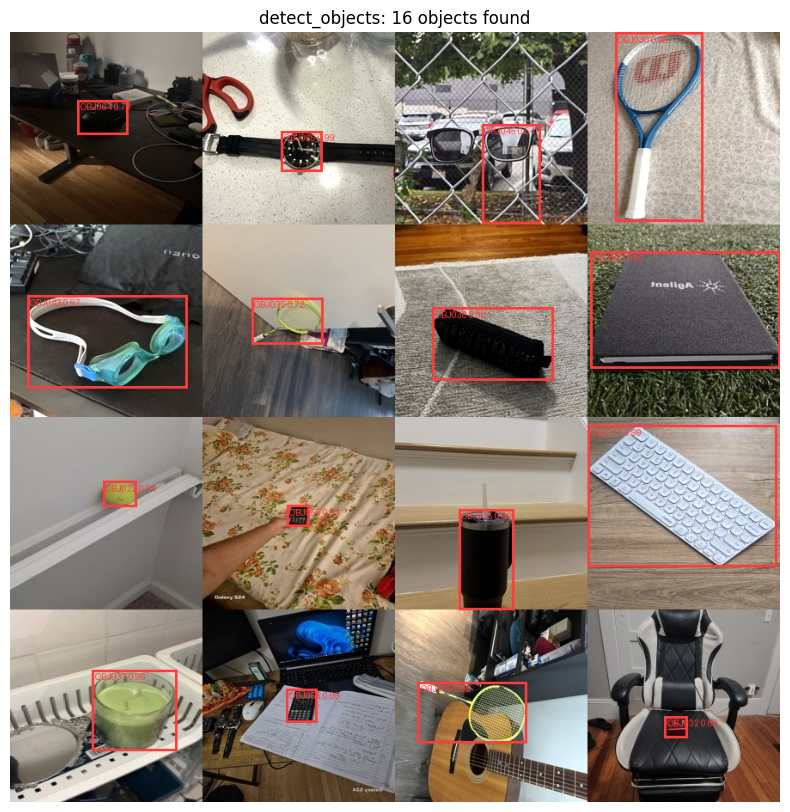

test_0001_4x4.jpg: 18 detections before, 16 after one-per-cell filtering

removed:
object_id                name  confidence                          box  row  col
   OBJ045 Wayfarer Sunglasses       0.360 [484.4, 111.0, 546.4, 153.1]    0    2
   OBJ027         Tennis ball       0.291 [297.1, 309.9, 364.1, 360.7]    1    1

final result:
object_id                  name  confidence                          box  row  col
   OBJ064         RGB Projector       0.788   [78.5, 79.1, 137.5, 119.3]    0    0
   OBJ065          Analog watch       0.993 [315.5, 115.1, 363.3, 162.6]    0    1
   OBJ045   Wayfarer Sunglasses       0.539 [549.3, 107.2, 617.6, 223.1]    0    2
   OBJ030         Tennis racket       0.977   [704.1, 0.9, 806.1, 220.0]    0    3
   OBJ043      Swimming Goggels       0.973  [20.1, 306.7, 206.2, 414.7]    1    0
   OBJ035      Badminton racket       0.717 [281.2, 309.5, 364.3, 363.4]    1    1
   OBJ036           Pencil case       0.960 [491.5, 320.6, 632.1, 405.1]    1 

In [ ]:
def detect_objects(image, conf=0.25, tile=224, one_per_cell=True, show=False):
    """Detect objects in a grid image.

    image: file path, PIL image or numpy array
    one_per_cell: keep only the most confident detection in each grid cell (chosen in Step 4)
    returns: list of dicts with object_id, name, confidence, box [x1, y1, x2, y2] in pixels, and grid row/col
    """
    if isinstance(image, (str, Path)):
        image = Image.open(image).convert("RGB")
    res = model.predict(image, imgsz=1120, conf=conf, verbose=False)[0]
    names = globals().get("NAMES", {})
    out = []
    for c, s, b in zip(res.boxes.cls.tolist(), res.boxes.conf.tolist(), res.boxes.xyxy.tolist()):
        oid = model.names[int(c)]
        x1, y1, x2, y2 = [round(v, 1) for v in b]
        out.append({"object_id": oid, "name": names.get(oid, ""), "confidence": round(s, 3),
                    "box": [x1, y1, x2, y2],
                    "row": int(((y1 + y2) / 2) // tile), "col": int(((x1 + x2) / 2) // tile)})
    if one_per_cell:
        best = {}
        for d in out:
            k = (d["row"], d["col"])
            if k not in best or d["confidence"] > best[k]["confidence"]:
                best[k] = d
        out = list(best.values())
    out.sort(key=lambda d: (d["row"], d["col"]))
    if show:
        img = image if isinstance(image, Image.Image) else Image.fromarray(image)
        img = img.copy(); dr = ImageDraw.Draw(img)
        for d in out:
            dr.rectangle(d["box"], outline=(255, 60, 60), width=3)
            dr.text((d["box"][0] + 3, d["box"][1] + 2), f'{d["object_id"]} {d["confidence"]:.2f}', fill=(255, 60, 60))
        plt.figure(figsize=(10, 10)); plt.imshow(img); plt.axis("off")
        plt.title(f"detect_objects: {len(out)} objects found"); plt.show()
    return out


before = detect_objects(demo, one_per_cell=False)
found = detect_objects(demo, show=True)
json.dump({"image": demo.name, "detections": found}, open(EVAL_DIR / "detect_objects_final.json", "w"), indent=2)

print(f"{demo.name}: {len(before)} detections before, {len(found)} after one-per-cell filtering")
removed = [d for d in before if d not in found]
print("\nremoved:")
print(pd.DataFrame(removed).to_string(index=False))
print("\nfinal result:")
print(pd.DataFrame(found).to_string(index=False))

**Output.** On `test_0001_4x4`, the filter reduced the result from 18 detections to **16**, exactly one per cell of the 4x4 grid. The two removed detections were the ones identified in Step 3:
- the duplicate Wayfarer Sunglasses box (OBJ045, confidence 0.360) in row 0, column 2
- the Tennis ball label (OBJ027, confidence 0.291) that overlapped the Badminton racket in row 1, column 1

In both cells the more confident detection was kept. The final result is saved to `evaluation/detect_objects_final.json`.

`detect_objects` is the final detection function for assignment requirement 3. It takes any grid image and returns the object ID, name, confidence, bounding box and grid cell of every object it finds.